## Análise 3: sazonalidade mensal dos atendimentos entre 2022 e 2024

**Perguntas:** É possível identificar um padrão sazonal nos atendimentos da Defesa Civil do Recife recorrente em diferentes anos no intervalo de 2022 a 2024? Em que meses há maior demanda? Qual o efeito do alto volume de chuvas de 2022 em comparação com o restante do triênio? \
\
Para essas questões, em combinação da **fato_atendimento** com a **dim_tempo**, utilizaram-se a chave **id_tempo_registro_sk** e o indicador **flag_data_inconsistente**, de forma que se considerassem apenas as datas válidas registradas no banco de dados durante o período estudado.

### Bibliotecas e conexão

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv("../.env")
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
cores = {2022: "#2a78d6", 2023: "#eb6834", 2024: "#1baf7a"}


def ler_consulta(arquivo):
    """Lê um arquivo .sql da pasta analises/ e devolve o resultado como DataFrame."""
    consulta = open(f"../analises/{arquivo}", encoding="utf-8").read()
    return pd.read_sql(text(consulta), con=engine)

### Escopo de dados

Foram considerados apenas os atendimentos cujo registro não apresentava inconformidades.

In [2]:
escopo = pd.read_sql(text("""
    SELECT COALESCE(t.ano::TEXT, 'total') AS ano,
           COUNT(*) AS total_atendimentos,
           COUNT(*) FILTER (WHERE NOT f.flag_data_inconsistente) AS registros_considerados,
           COUNT(*) FILTER (WHERE f.flag_data_inconsistente) AS registros_descartados
    FROM elt.fato_atendimento AS f
    INNER JOIN elt.dim_tempo AS t ON t.id_tempo_sk = f.id_tempo_registro_sk
    WHERE t.ano BETWEEN 2022 AND 2024
    GROUP BY ROLLUP (t.ano)
    ORDER BY t.ano;
"""), con=engine)
escopo

,ano,total_atendimentos,registros_considerados,registros_descartados
0,2022,84652,84405,247
1,2023,77273,76067,1206
2,2024,74235,74102,133
3,total,236160,234574,1586


### Consulta geral

In [3]:
sazonalidade_mensal = ler_consulta("analise_3_sazonalidade_mensal.sql")
sazonalidade_mensal

,mes,nome_mes,indice_2022,indice_2023,indice_2024,indice_medio_mensal,mediana_indice_mensal,cv_mensal,posicao_media,posicao_mediana,classificacao_mediana
0,1,janeiro,0.84,1.01,1.01,0.96,1.01,0.10,7,6,"média demanda, estável"
1,2,fevereiro,0.77,1.17,0.94,0.96,0.94,0.21,6,7,"média demanda, instável"
2,3,março,1.49,1.62,1.47,1.52,1.49,0.05,3,2,"alta demanda, estável"
3,4,abril,1.63,1.24,1.71,1.53,1.63,0.16,2,1,"alta demanda, instável"
4,5,maio,2.21,1.34,1.34,1.63,1.34,0.31,1,3,"alta demanda, instável"
5,6,junho,1.33,1.05,1.17,1.18,1.17,0.12,4,4,"média demanda, estável"
6,7,julho,0.94,1.07,1.18,1.06,1.07,0.12,5,5,"média demanda, estável"
7,8,agosto,0.83,0.91,0.91,0.88,0.91,0.05,8,8,"média demanda, estável"
8,9,setembro,0.60,0.64,0.66,0.63,0.64,0.05,9,9,"baixa demanda, estável"
9,10,outubro,0.56,0.71,0.62,0.63,0.62,0.12,10,10,"baixa demanda, estável"


A tabela gerada pela consulta identifica, nas colunas 1 e 2, o mês e o respectivo nome; em sequência, apresenta:
* os **índices mensais** (2022—2024), oriundos da divisão do _total de atendimentos do mês_ pela _média mensal de atendimentos de todo o ano_, para determinado ano;
* o **índice médio mensal**, obtido pela média aritmética dos _índices mensais_ de certo mês, contabilizados todos os anos;
* a **mediana do índice mensal**, a qual, embora, assim como o _índice médio_, se refira aos _índices mensais_, atenua o impacto de valores extremos e notabiliza o comportamento típico do mês;
* o **coeficiente de variação mensal**, advindo da divisão do _desvio-padrão do índice mensal_ pelo _índice médio mensal_;
* a **posição pela média**, que ordena o mês com base no _índice médio mensal_;
* a **posição pela mediana**, para o ranqueamento do mês relativamente à _mediana do índice mensal_;
* a **classificação** do mês  quanto a:
    * **demanda**: fundamentada na _mediana do índice mensal_:
        * alta (superior ou igual a 1,2);
        * média (entre 1,2 e 0,8); ou
        * baixa (inferior ou igual a 0,8).
    * **estabilidade**: guiada pelo _coeficiente de variação mensal_:
        * estável (inferior ou igual a 0,15); ou
        * instável (superior a 0,15).

#### Gráfico 1: índice mensal e mediana do índice mensal

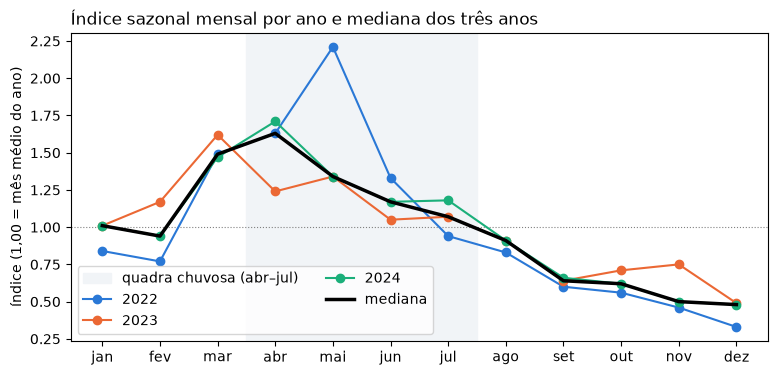

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(3.5, 7.5, color="#F1F4F7", label="quadra chuvosa (abr–jul)")
ax.axhline(1, color="gray", lw=0.8, ls=":")
for ano, cor in cores.items():
    ax.plot(sazonalidade_mensal["mes"], sazonalidade_mensal[f"indice_{ano}"], marker="o", color=cor, label=str(ano))
ax.plot(sazonalidade_mensal["mes"], sazonalidade_mensal["mediana_indice_mensal"], color="black", lw=2.5, label="mediana")
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("índice (1,00 = mês médio do ano)")
ax.set_title("Índice sazonal mensal por ano e mediana dos três anos", loc="left")
ax.legend(ncol=2, loc="lower left")
plt.show()

#### Tabela comparativa entre média e mediana do índice mensal

In [5]:
sazonalidade_mensal[["nome_mes", "indice_medio_mensal", "mediana_indice_mensal", "posicao_media", "posicao_mediana"]].sort_values("posicao_mediana")

,nome_mes,indice_medio_mensal,mediana_indice_mensal,posicao_media,posicao_mediana
3,abril,1.53,1.63,2,1
2,março,1.52,1.49,3,2
4,maio,1.63,1.34,1,3
5,junho,1.18,1.17,4,4
6,julho,1.06,1.07,5,5
0,janeiro,0.96,1.01,7,6
1,fevereiro,0.96,0.94,6,7
7,agosto,0.88,0.91,8,8
8,setembro,0.63,0.64,9,9
9,outubro,0.63,0.62,10,10


#### Mapa de calor 1: índice mensal por ano

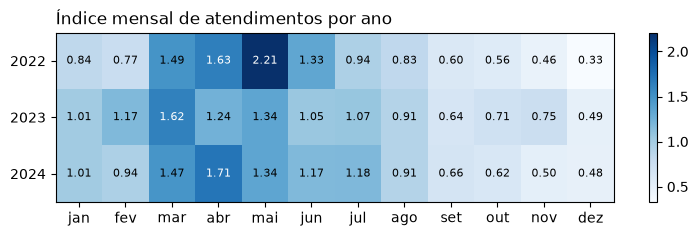

In [6]:
matriz = sazonalidade_mensal.set_index("nome_mes")[["indice_2022", "indice_2023", "indice_2024"]].T
fig, ax = plt.subplots(figsize=(9, 2.2))
im = ax.imshow(matriz.astype(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(12), meses)
ax.set_yticks(range(3), ["2022", "2023", "2024"])
for i in range(3):
    for j in range(12):
        valor = float(matriz.iloc[i, j])
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color="white" if valor > 1.5 else "black")
ax.set_title("Índice mensal de atendimentos por ano", loc="left")
fig.colorbar(im, ax=ax)
plt.show()

#### Gráfico 2: mediana do índice mensal vs. coeficiente de variação

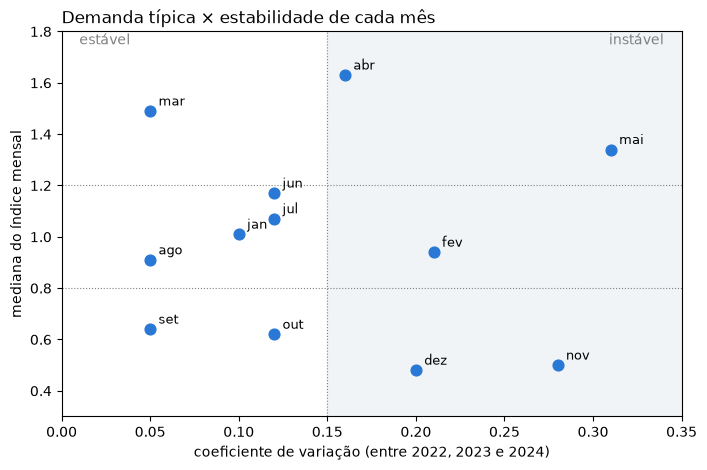

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(0.15, 0.35, color="#F1F4F7")
ax.axvline(0.15, color="gray", lw=0.8, ls=":")
for limite in (0.8, 1.2):
    ax.axhline(limite, color="gray", lw=0.8, ls=":")
ax.scatter(sazonalidade_mensal["cv_mensal"], sazonalidade_mensal["mediana_indice_mensal"],
           s=60, color="#2a78d6", zorder=3)
for _, linha in sazonalidade_mensal.iterrows():
    ax.annotate(meses[linha["mes"] - 1], (linha["cv_mensal"], linha["mediana_indice_mensal"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.text(0.01, 1.75, "estável", color="gray")
ax.text(0.34, 1.75, "instável", color="gray", ha="right")
ax.set_xlim(0, 0.35)
ax.set_ylim(0.3, 1.8)
ax.set_xlabel("coeficiente de variação (entre 2022, 2023 e 2024)")
ax.set_ylabel("mediana do índice mensal")
ax.set_title("Demanda típica × estabilidade de cada mês", loc="left")
plt.show()

#### Gráfico 3: amplitude por mês

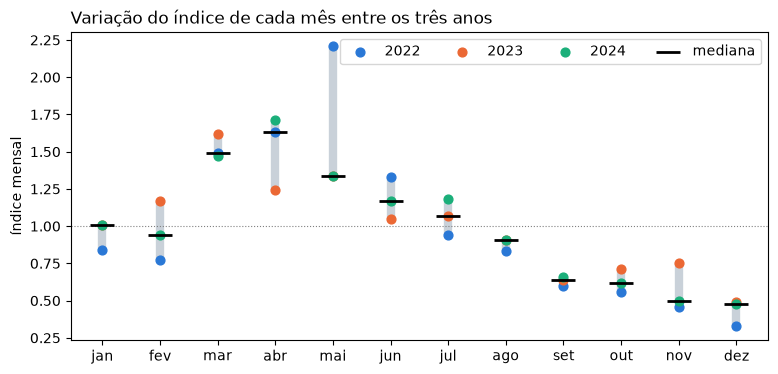

In [8]:
indices = sazonalidade_mensal[["indice_2022", "indice_2023", "indice_2024"]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.vlines(sazonalidade_mensal["mes"], indices.min(axis=1), indices.max(axis=1),
          color="#C9D1D9", lw=6, zorder=1)
for ano, cor in cores.items():
    ax.scatter(sazonalidade_mensal["mes"], sazonalidade_mensal[f"indice_{ano}"],
               color=cor, s=40, label=str(ano), zorder=3)
ax.scatter(sazonalidade_mensal["mes"], sazonalidade_mensal["mediana_indice_mensal"],
           marker="_", s=300, lw=2, color="black", label="mediana", zorder=4)
ax.axhline(1, color="gray", lw=0.8, ls=":")
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("índice mensal")
ax.set_title("Variação do índice de cada mês entre os três anos", loc="left")
ax.legend(ncol=4, loc="upper right")
plt.show()

#### Gráfico 4: comparativo entre 2022 e média do triênio 2022—2024

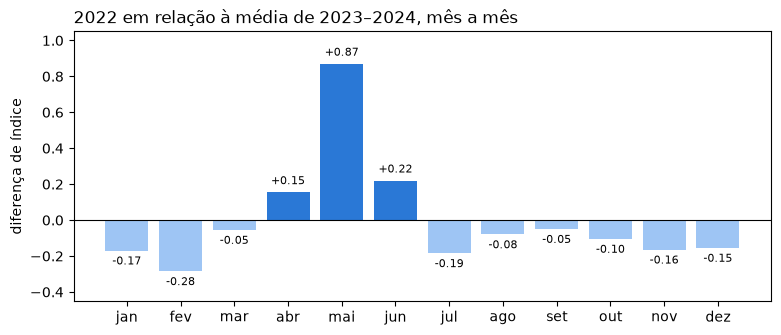

In [9]:
desvio_2022 = (sazonalidade_mensal["indice_2022"].astype(float)
               - sazonalidade_mensal[["indice_2023", "indice_2024"]].astype(float).mean(axis=1))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(sazonalidade_mensal["mes"], desvio_2022,
       color=["#2a78d6" if d >= 0 else "#9ec5f4" for d in desvio_2022])
ax.axhline(0, color="black", lw=0.8)
for mes, d in zip(sazonalidade_mensal["mes"], desvio_2022):
    ax.text(mes, d + (0.03 if d >= 0 else -0.03), f"{d:+.2f}", ha="center",
            va="bottom" if d >= 0 else "top", fontsize=8)
ax.set_xticks(range(1, 13), meses)
ax.set_ylim(-0.45, 1.05)
ax.set_ylabel("diferença de índice")
ax.set_title("2022 em relação à média de 2023–2024, mês a mês", loc="left")
plt.show()

### Consulta complementar 1: total de atendimentos por mês

In [10]:
totais_mensais = ler_consulta("analise_3_total_atendimentos_mes.sql")
totais_mensais

,mes,nome_mes,atendimentos_2022,atendimentos_2023,atendimentos_2024,atendimentos_trienio
0,1,janeiro,5926,6423,6259,18608
1,2,fevereiro,5443,7448,5830,18721
2,3,março,10455,10247,9057,29759
3,4,abril,11482,7868,10559,29909
4,5,maio,15530,8497,8259,32286
5,6,junho,9381,6628,7255,23264
6,7,julho,6588,6806,7295,20689
7,8,agosto,5859,5755,5632,17246
8,9,setembro,4200,4037,4096,12333
9,10,outubro,3966,4511,3836,12313


### Consulta complementar 2: grau de risco dos atendimentos por mês

In [11]:
risco_mensal = ler_consulta("analise_3_risco_mes.sql")

colunas = {"": "triênio", "_2022": "2022", "_2023": "2023", "_2024": "2024"}

def tabela_indicador(prefixo):
    tabela = risco_mensal.set_index("nome_mes")[[prefixo + sufixo for sufixo in colunas]]
    tabela.columns = list(colunas.values())
    tabela.index.name = "mês"
    return tabela

print("Total de atendimentos por mês no triênio")
display(risco_mensal.set_index("nome_mes")[["total_atendimentos"]].rename_axis("mês"))

print("Porcentagem de atendimentos com grau de risco não informado ou classificado como sem risco")
display(tabela_indicador("pct_risco_nao_informado"))

print("Porcentagem de graus R3 e R4 entre os atendimentos com risco informado")
display(tabela_indicador("pct_risco_r3_r4"))

print("Atendimentos de grau R4")
display(tabela_indicador("atendimentos_r4").astype("Int64"))


Total de atendimentos por mês no triênio


,total_atendimentos
mês,
janeiro,18608
fevereiro,18721
março,29759
abril,29909
maio,32286
junho,23264
julho,20689
agosto,17246
setembro,12333


Porcentagem de atendimentos com grau de risco não informado ou classificado como sem risco


,triênio,2022,2023,2024
mês,,,,
janeiro,43.5,34.5,41.7,54.0
fevereiro,46.5,43.7,42.4,54.5
março,50.9,48.0,48.6,56.8
abril,55.2,53.1,51.7,60.0
maio,56.3,53.7,51.9,65.6
junho,61.3,63.3,59.5,60.4
julho,58.8,58.9,59.3,58.2
agosto,56.1,58.5,56.3,53.4
setembro,53.0,59.9,53.9,45.0


Porcentagem de graus R3 e R4 entre os atendimentos com risco informado


,triênio,2022,2023,2024
mês,,,,
janeiro,50.1,47.1,50.4,53.7
fevereiro,55.1,49.7,58.6,55.6
março,52.6,52.1,53.5,52.2
abril,51.5,50.2,55.1,49.9
maio,57.9,58.3,62.6,50.0
junho,72.2,76.8,68.5,70.1
julho,72.9,64.9,82.7,71.1
agosto,77.6,65.3,88.3,78.8
setembro,68.1,68.2,88.5,51.2


Atendimentos de grau R4


,triênio,2022,2023,2024
mês,,,,
janeiro,307,20,176,111
fevereiro,473,24,307,142
março,474,59,215,200
abril,334,44,129,161
maio,672,359,138,175
junho,1067,737,189,141
julho,763,492,159,112
agosto,351,240,62,49
setembro,217,115,35,67


#### Gráfico 5: percentual de atendimentos R3 e R4 a cada mês, por ano e no triênio

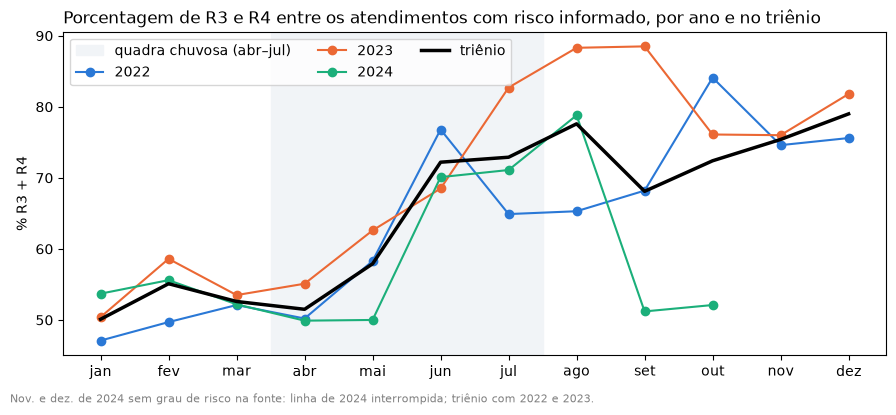

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(3.5, 7.5, color="#F1F4F7", label="quadra chuvosa (abr–jul)")
for ano, cor in cores.items():
    ax.plot(risco_mensal["mes"], risco_mensal[f"pct_risco_r3_r4_{ano}"],
            marker="o", color=cor, label=str(ano))
ax.plot(risco_mensal["mes"], risco_mensal["pct_risco_r3_r4"],
        color="black", lw=2.5, label="triênio")
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("% R3 + R4")
ax.set_title("Porcentagem de R3 e R4 entre os atendimentos com risco informado, por ano e no triênio", loc="left")
ax.legend(ncol=3, loc="upper left")
fig.text(0.01, -0.02, "Nov. e dez. de 2024 sem grau de risco na fonte: linha de 2024 interrompida; "
         "triênio com 2022 e 2023.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

#### Gráfico 6: total de atendimentos de grau R4 por mês e por ano

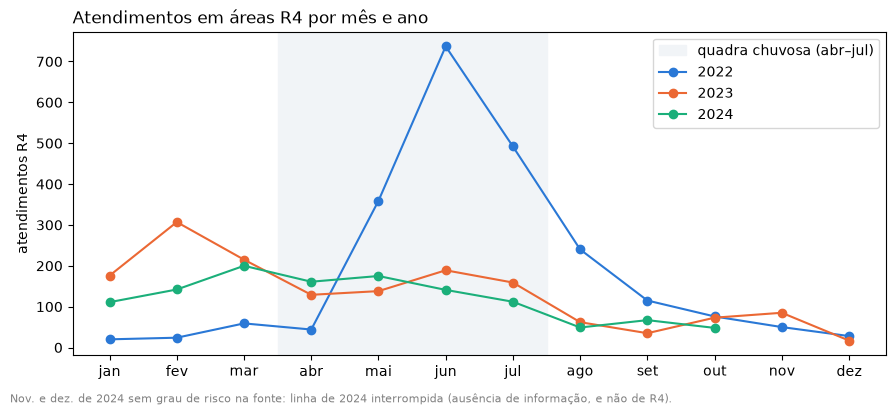

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(3.5, 7.5, color="#F1F4F7", label="quadra chuvosa (abr–jul)")
for ano, cor in cores.items():
    ax.plot(risco_mensal["mes"], risco_mensal[f"atendimentos_r4_{ano}"],
            marker="o", color=cor, label=str(ano))
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("atendimentos R4")
ax.set_title("Atendimentos em áreas R4 por mês e ano", loc="left")
ax.legend(loc="upper right")
fig.text(0.01, -0.02, "Nov. e dez. de 2024 sem grau de risco na fonte: linha de 2024 interrompida "
         "(ausência de informação, e não de R4).", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

### Consulta complementar 3: índice mensal por categoria de ação

In [14]:
categorias = ler_consulta("analise_3_indice_categoria.sql")
categorias

,categoria_acao,mes,atendimentos_trienio,mediana_indice_mensal
0,Assistência humanitária,1,92.0,0.50
1,Assistência humanitária,2,59.0,0.27
2,Assistência humanitária,3,64.0,0.39
3,Assistência humanitária,4,181.0,0.50
4,Assistência humanitária,5,515.0,1.37
...,...,...,...,...
67,Prevenção e orientação,8,250.0,0.08
68,Prevenção e orientação,9,79.0,0.03
69,Prevenção e orientação,10,148.0,0.01
70,Prevenção e orientação,11,191.0,0.01


#### Mapa de calor 2: índice mensal por categoria de ação, exceto "Remoção de famílias"

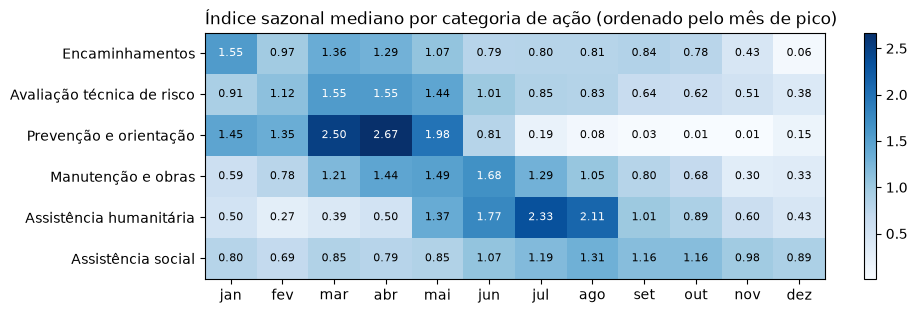

In [15]:
matriz_categorias = categorias.pivot(index="categoria_acao", columns="mes",
                                     values="mediana_indice_mensal").astype(float)
ordem = matriz_categorias.idxmax(axis=1).sort_values(kind="stable").index
matriz_categorias = matriz_categorias.loc[ordem]

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(matriz_categorias, cmap="Blues", aspect="auto")
for i in range(matriz_categorias.shape[0]):
    for j in range(12):
        valor = matriz_categorias.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if valor > 1.5 else "black")
ax.set_xticks(range(12), meses)
ax.set_yticks(range(len(ordem)), ordem)
ax.set_title("Índice sazonal mediano por categoria de ação (ordenado pelo mês de pico)", loc="left")
fig.colorbar(im, ax=ax)
plt.show()

### Consulta complementar 4: atendimentos categorizados como "Remoção de famílias"

In [16]:
remocoes_mensais = ler_consulta("analise_3_remocoes_mes.sql")
remocoes_mensais

,mes,remocoes_2022,remocoes_2023,remocoes_2024,remocoes_trienio
0,janeiro,0,0,1,1
1,fevereiro,0,71,0,71
2,março,0,0,3,3
3,abril,0,1,9,10
4,maio,66,4,0,70
5,junho,373,2,4,379
6,julho,349,4,1,354
7,agosto,92,0,0,92
8,setembro,4,0,2,6
9,outubro,0,0,0,0


### Inferências

#### Da consulta geral
A análise da tabela de consulta e dos gráficos permite identificar a correspondência entre o aumento do índice mensal de atendimentos e a aproximação da quadra chuvosa do ano, esta atribuída ao período de abril a julho — em que se observa um salto no número de atendimentos da Defesa Civil do Recife. \
\
Esse comportamento é respaldado no clima da cidade: tropical úmido com estação seca no verão (As), pela classificação de Köppen [1]. Isso demonstra, também, o padrão de demanda por atendimentos comum ao triênio, cujo salto antecede a época chuvosa em um ou dois meses. \
\
Nessa perspectiva, evidencia-se o impacto dos eventos meteorológicos de maio de 2022 na quantidade de atendimentos registrados. Matérias do jornal Folha de PE, naquele ano, mostram que as 24 horas finalizadas na manhã de 25/5/2022 marcaram o 3.º maior volume de chuva na mesma janela de tempo desde 1970, em apontamento do INMET [2]; e a pluviosidade total do mês (686 mm) superou em cerca de 110% a média esperada, de 329 mm, segundo a APAC [3]. \
\
Os cálculos da média e da mediana mensais, contudo, sugerem que, não obstante detenha o maior pico do intervalo estudado (índice 2,21 em 2022), maio não é o mês em que mais costuma haver atendimentos, dentre os 3 anos; a média considera valores extremos, porém, quando estes se abstraem, é abril que ocupa o 1.º lugar (1,63) em demanda típica, e maio cai da 1.ª posição pela média (1,63) para a 3.ª (1,34) pela mediana. \
\
Concomitantemente, a comparação entre a mediana e o coeficiente de variação de cada mês desenha o nível de estabilidade deste ao longo dos três anos, justificado pela amplitude do índice mensal nesse recorte: a instabilidade de maio e dezembro provém de 2022; a de fevereiro, abril e novembro, de 2023. \
\
Por conseguinte, é notório o efeito de fenômenos extremos sobre a análise estatística de determinado período, a qual requer parâmetros adicionais para que se imprima uma sazonalidade verossímil nos atendimentos da Defesa Civil do Recife no triênio. \
\
Complementa-se, ainda, que a ampliação da amostra potencializaria a fidelidade das conclusões do estudo.
\
#### Das consultas complementares
Os números absolutos de atendimentos por mês dimensionam o cenário extraído pela consulta geral: os de março a junho, somados os três anos, respondem por quase metade do total registrado. Em 2022, o total de maio quase dobrou com relação ao de 2023 e 2024. \
\
Todavia, a crescente no número de atendimentos não necessariamente acompanha uma maior gravidade das ocorrências. Dentre aqueles com grau informado, a proporção em pontos de risco alto (R3) e muito alto (R4) concentra-se majoritariamente no segundo semestre em todos os anos, mas sem ápice uniforme: este sempre acontece em meses distintos. \
\
Apesar disso, o ano de 2022 apresenta um máximo expressivo de atendimentos em áreas R4 entre maio e junho, o que corrobora o diagnóstico sobre excepcionalidade das chuvas no momento. \
\
Em última instância, as ações de prevenção e orientação na abertura da quadra chuvosa, seguidas pelas de assistência humanitária durante ela, denotam uma atuação da Defesa Civil que migra da profilaxia ao auxílio à população por danos climáticos. \
\
O panorama exposto ratifica a anomalia que abrange o fim de maio e o princípio de junho de 2022 [4], acarretada pelo excepcional volume pluviométrico, o qual maximizou sobremodo os atendimentos registrados pelo órgão, particularmente em regiões de alto risco, e deformou a rotina sazonal de atendimentos, nomeadamente na categoria de remoção de famílias.

### Referências externas
1. ALVARES, C. A. et al. Köppen's climate classification map for Brazil. Meteorologische Zeitschrift, v. 22,
n. 6, p. 711–728, 2013. DOI: 10.1127/0941-2948/2013/0507.
2. FOLHA DE PERNAMBUCO. Acumulado de chuvas das últimas 24h no Recife é o terceiro maior dos
últimos 50 anos, diz prefeito. 25 maio 2022. Disponível em: https://www.folhape.com.br/noticias/acumulado-de-chuvas-das-ultimas-24h-no-recife-e-um-dos-maiores-dos/228053/
3. FOLHA DE PERNAMBUCO. Junho pode ter chuvas acima da média histórica na RMR, diz Apac. 2022.
Disponível em: https://www.folhape.com.br/noticia/detalhe/junho-pode-ter-chuvas-acima-da-media-historica-na-rmr-diz-apac/229117/
4. FOLHA DE PERNAMBUCO. Maior tragédia do século em Pernambuco, mortes pelas chuvas de 2022
superam total da cheia de 1975. 2 jun. 2022. Disponível em: https://www.folhape.com.br/noticia/detalhe/maior-tragedia-do-seculo-em-pernambuco-mortes-pelas-chuvas-de-2022/228963/